Menjalankan dengan 1 worker...
Selesai worker 1: 0.0213 detik
Menjalankan dengan 2 worker...
Selesai worker 2: 0.0240 detik
Menjalankan dengan 4 worker...
Selesai worker 4: 0.0330 detik
Menjalankan dengan 8 worker...
Selesai worker 8: 0.0541 detik


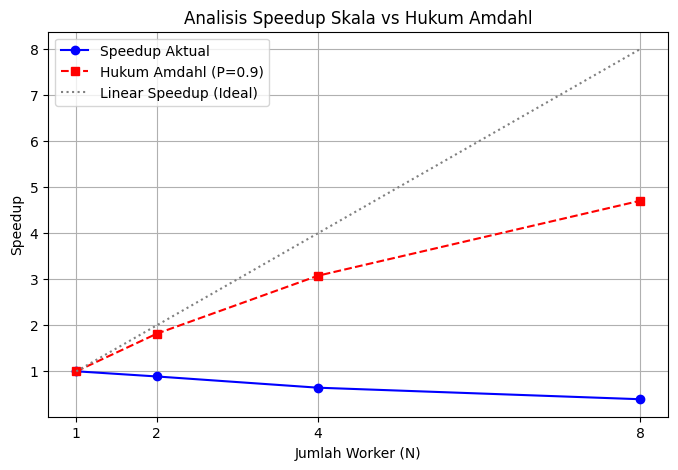

In [1]:
import time
import multiprocessing as mp
import matplotlib.pyplot as plt
import sys

def cek_prima(n):
    if n < 2:
        return False
    for i in range(2, int(n**0.5) + 1):
        if n % i == 0:
            return False
    return True

def hitung_prima(rentang):
    mulai, selesai = rentang
    return [n for n in range(mulai, selesai) if cek_prima(n)]

if __name__ == '__main__':
    batas_awal = 1
    batas_akhir = 5

    workers_list = [1, 2, 4, 8]
    waktu_eksekusi = {}

    jumlah_bagian = 8
    chunk = (batas_akhir - batas_awal) // jumlah_bagian
    ranges = [(i * chunk + 1, (i + 1) * chunk if i < 7 else batas_akhir) for i in range(jumlah_bagian)]

    metode_ctx = 'spawn' if sys.platform.startswith('win') else 'fork'
    ctx = mp.get_context(metode_ctx)

    for w in workers_list:
        print(f"Menjalankan dengan {w} worker...")
        start_time = time.time()

        with ctx.Pool(processes=w) as pool:
            hasil = pool.map(hitung_prima, ranges)

        end_time = time.time()
        durasi = end_time - start_time
        waktu_eksekusi[w] = durasi
        print(f"Selesai worker {w}: {durasi:.4f} detik")

    t_1 = waktu_eksekusi[1]
    speedup_aktual = [t_1 / waktu_eksekusi[w] for w in workers_list]

    P = 0.90
    speedup_amdahl = [1 / ((1 - P) + (P / w)) for w in workers_list]

    plt.figure(figsize=(8, 5))
    plt.plot(workers_list, speedup_aktual, marker='o', label='Speedup Aktual', color='blue')
    plt.plot(workers_list, speedup_amdahl, marker='s', linestyle='--', label=f'Hukum Amdahl (P={P})', color='red')
    plt.plot(workers_list, workers_list, linestyle=':', label='Linear Speedup (Ideal)', color='gray')

    plt.xlabel('Jumlah Worker (N)')
    plt.ylabel('Speedup')
    plt.title('Analisis Speedup Skala vs Hukum Amdahl')
    plt.xticks(workers_list)
    plt.legend()
    plt.grid(True)
    plt.show()

Linear Speedup (Ideal): Garis diagonal menunjukkan bahwa penambahan worker berbanding lurus dengan peningkatan kecepatan.

Kurva Aktual vs Hukum Amdahl: Hasil aktual menunjukkan bahwa penambahan worker justru meningkatkan waktu eksekusi akibat overhead proses dan keterbatasan core CPU.

In [13]:

import multiprocessing as mp
import random
import time

JUMLAH_PROSES = 4
JUMLAH_ANGKA = 1_000_000

def pekerja_queue(queue, seed):
    rng = random.Random(seed)
    subtotal = sum(
        rng.randint(1, 100) for _ in range(JUMLAH_ANGKA)
    )
    queue.put(subtotal)

def pekerja_value(shared_value, lock, seed):
    rng = random.Random(seed)
    subtotal = sum(
        rng.randint(1, 100) for _ in range(JUMLAH_ANGKA)
    )

    with lock:
        shared_value.value += subtotal

if __name__ == "__main__":
    ctx = mp.get_context("fork")

    queue = ctx.Queue()
    proses = []
    mulai = time.perf_counter()

    for i in range(JUMLAH_PROSES):
        p = ctx.Process(target=pekerja_queue, args=(queue, i))
        p.start()
        proses.append(p)

    for p in proses:
        p.join()

    total_queue = sum(queue.get() for _ in range(JUMLAH_PROSES))
    waktu_queue = time.perf_counter() - mulai
    queue.close()

    shared_value = ctx.Value("q", 0)
    lock = ctx.Lock()
    proses = []
    mulai = time.perf_counter()

    for i in range(JUMLAH_PROSES):
        p = ctx.Process(
            target=pekerja_value,
            args=(shared_value, lock, i)
        )
        p.start()
        proses.append(p)

    for p in proses:
        p.join()

    total_value = shared_value.value
    waktu_value = time.perf_counter() - mulai

    print("=== HASIL PENGUJIAN ===")
    print(f"Total Queue        : {total_queue}")
    print(f"Waktu Queue        : {waktu_queue:.4f} detik")
    print(f"Total Shared Memory: {total_value}")
    print(f"Waktu Shared Memory: {waktu_value:.4f} detik")


=== HASIL PENGUJIAN ===
Total Queue        : 202026957
Waktu Queue        : 3.4034 detik
Total Shared Memory: 202026957
Waktu Shared Memory: 3.7080 detik


ANALISA NOMOR 2

Berdasarkan hasil pengujian, metode Queue lebih cepat dengan waktu 3,4034 detik, sedangkan Shared Memory membutuhkan waktu 3,7080 detik. Selisih waktu keduanya adalah 0,3046 detik. Kedua metode menghasilkan total penjumlahan yang sama, yaitu 202.026.957, sehingga hasil perhitungannya konsisten.
Queue lebih cepat pada pengujian ini karena setiap proses hanya mengirimkan subtotal satu kali kepada proses utama. Sementara itu, Shared Memory menggunakan Value dan Lock untuk memperbarui nilai bersama. Meskipun penguncian hanya dilakukan satu kali per proses pada program ini, sinkronisasi dan akses memori bersama tetap memiliki overhead.

In [21]:

import multiprocessing
import time

JUMLAH_CONSUMERS = 3

def producer(q, jumlah_item, nama="Producer"):
    for i in range(jumlah_item):
        item = f"item-{i}"
        q.put(item)
        print(f"[{nama}] menghasilkan: {item}")

    for _ in range(JUMLAH_CONSUMERS):
        q.put(None)


def consumer(q, nama="Consumer"):
    while True:
        item = q.get()

        if item is None:
            break

        hasil = 0
        for i in range(1_000_000):
            hasil += i * i

        print(f"[{nama}] memproses: {item}")


if __name__ == "__main__":
    q = multiprocessing.Queue()

    p_producer = multiprocessing.Process(
        target=producer,
        args=(q, 6)
    )

    p_consumers = [
        multiprocessing.Process(
            target=consumer,
            args=(q, f"Consumer-{i}")
        )
        for i in range(1, JUMLAH_CONSUMERS + 1)
    ]

    mulai = time.perf_counter()

    for p in p_consumers:
        p.start()

    p_producer.start()
    p_producer.join()

    for p in p_consumers:
        p.join()

    selesai = time.perf_counter()

    print("\nSemua item sudah diproduksi dan dikonsumsi.")
    print(f"Waktu eksekusi: {selesai - mulai:.4f} detik")

    q.close()


[Producer] menghasilkan: item-0
[Producer] menghasilkan: item-1
[Producer] menghasilkan: item-2
[Producer] menghasilkan: item-3
[Producer] menghasilkan: item-4
[Producer] menghasilkan: item-5
[Consumer-2] memproses: item-1
[Consumer-3] memproses: item-2[Consumer-1] memproses: item-0

[Consumer-3] memproses: item-4
[Consumer-1] memproses: item-5
[Consumer-2] memproses: item-3

Semua item sudah diproduksi dan dikonsumsi.
Waktu eksekusi: 0.7216 detik


A. Perubahan Struktur Kode
Struktur utama Producer–Consumer tidak banyak berubah. Perbedaannya terletak pada penggunaan multiprocessing.Queue() sebagai media komunikasi dan multiprocessing.Process untuk menjalankan Producer dan Consumer sebagai proses terpisah.

B. Perbedaan Performa
Multiprocessing menunjukkan waktu eksekusi yang lebih singkat pada hasil pengujian dibandingkan program pada pertemuan 2. Hal ini bisa terjadi karena pekerjaan CPU-bound dapat dijalankan secara paralel pada beberapa core CPU.

Manager() lebih cocok digunakan ketika beberapa proses perlu berbagi data yang kompleks, seperti dictionary atau list, dan data tersebut sering berubah. Contohnya, sistem pemantauan yang menyimpan status beberapa proses dalam satu struktur data bersama. Manager() lebih mudah digunakan karena menyediakan objek yang dapat diakses oleh banyak proses.

Sebaliknya, Value atau Array lebih cocok untuk data sederhana seperti angka dan kumpulan angka yang membutuhkan akses cepat. Contohnya, program komputasi paralel yang menghitung total atau menyimpan hasil perhitungan dari beberapa proses.

Kesimpulannya, Manager() unggul dalam kemudahan dan fleksibilitas, sedangkan Value dan Array lebih efisien untuk data sederhana karena overhead-nya lebih rendah. Pemilihan metode bergantung pada kebutuhan program antara kemudahan pengelolaan data dan performa.